# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer: I think the high-survival profile is a first-class female child. Women and children were supposed to get on the lifeboats first, and first class was closer to the boat deck, so they would have a better shot at getting to one. I’d guess they were traveling with one parent or child and one sibling or spouse, since a small family could help each other. For the port, I don’t have a strong prediction. I don’t know enough about Cherbourg, Queenstown, or Southampton to say one was safer, so I’d rather check that in the data.

For the low-survival profile, I’d guess a third-class older man traveling alone. Men didn’t get priority for the boats, third class was farther from the deck, and an older man might have had a harder time getting there. If they were alone, they had no family member to help them. I’m less sure about the family counts, though. A big family might be worse than being alone because they’d be harder to move together, so I’d compare none, one, and two or more before deciding.

## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [1]:
# Import pandas as pd and matplotlib.pyplot as plt.
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Read data/titanic_passengers.csv into titanic_df.
titanic_df = pd.read_csv("data/titanic_passengers.csv")

In [3]:
# Display the first five rows.
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Display .info().
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
# Display the missing-value count for each feature.
titanic_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**What does one row represent? Which feature is the target, and what do its codes mean?**

Your answer: Each row is one passenger in this 891-row training file, not a complete list of everyone on the Titanic and not one row per family or ticket. The target is Survived. A code of 0 means the passenger did not survive, and 1 means the passenger survived.

Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `PassengerId` | Identifier | int64 | 0 |
| `Name` | Identifier | object | 0 |
| `Survived` | Categorical | int64 | 0 |
| `Pclass` | Categorical | int64 | 0 |
| `Sex` | Categorical | object | 0 |
| `Age` | Quantitative | float64 | 177 |
| `Parch` | Quantitative | int64 | 0 |
| `SibSp` | Quantitative | int64 | 0 |
| `Embarked` | Categorical | object | 2 |


## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.


| Age-group label | Exact rule (including boundary values) | Reason for this choice |
| --- | --- | --- |
| Child (0–15) | Age <= 15; includes 15, down to 0.42 | Keeps school-age children together; 15 is the last age before the adult groups. |
| Younger adult (16–39) | 16 <= Age <= 39; includes 16 and 39 | Separates younger adults from middle-aged adults; 16 is the first adult age and 39 is the last younger-adult age. |
| Middle-aged adult (40–59) | 40 <= Age <= 59; includes 40 and 59 | 40 is a clear midlife boundary; 59 is the last age before the older group. |
| Older adult (60+) | Age >= 60; includes 60, up to 80 | 60 is a recognizable older-adult cutoff. |
| Unknown | Age is missing | Kept separate so unknown ages are not counted as adults. |

**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer: I used four age groups: children 0–15, younger adults 16–39, middle-aged adults 40–59, and older adults 60+. The boundaries don’t overlap: 15 is a child, 16 starts the younger adult group, 39 is still younger adult, 40 starts the middle-aged group, 59 is still middle-aged, and 60 starts the older group. I split the adults because putting everyone 16–59 in one group would be very broad and could hide differences between younger and middle-aged adults. I kept unknown ages as their own “Unknown” group instead of treating them as adults, because age is missing and guessing would change the comparison. I’ll check the group sizes after I run the code.

Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [6]:
# Create age_group and display its category counts, including unknown ages.
titanic_df["age_group"] = "Unknown"

titanic_df.loc[titanic_df["Age"] <= 15, "age_group"] = "Child (0-15)"
titanic_df.loc[
    (titanic_df["Age"] >= 16) & (titanic_df["Age"] <= 39), "age_group"
] = "Younger adult (16-39)"
titanic_df.loc[
    (titanic_df["Age"] >= 40) & (titanic_df["Age"] <= 59), "age_group"
] = "Middle-aged adult (40-59)"
titanic_df.loc[titanic_df["Age"] >= 60, "age_group"] = "Older adult (60+)"

titanic_df["age_group"].value_counts().reindex(["Child (0-15)", "Younger adult (16-39)","Middle-aged adult (40-59)", "Older adult (60+)", "Unknown"]).to_frame("passenger_count")

,passenger_count
age_group,
Child (0-15),83
Younger adult (16-39),468
Middle-aged adult (40-59),137
Older adult (60+),26
Unknown,177


**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer: The only really small group is 60+ with 26 people. It’s enough to compare, but one person can move the percentage by about 4 points, so I’ll report the size and be careful with it. The child group has 83 people, which is on the small side but still usable. The 177 unknown ages are the bigger problem, but they’re not an age group, so I’ll leave them out and use the 714 people with known ages. I went from three groups to four before looking at survival. Splitting 16–59 into 16–39 and 40–59 lets me compare younger and middle-aged adults instead of lumping them together. I don’t want to split 60+ again because 70+ only has 7 people, and I don’t want to merge it with 40–59 because that would hide the older adults. The groups don’t have to be the same size because each percentage only uses the people in that group.

### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [7]:
# Display Parch and SibSp category counts; create any grouped features and display their counts.
print(titanic_df["Parch"].value_counts().sort_index())
print(titanic_df["SibSp"].value_counts().sort_index())

titanic_df["parch_group"] = "None"
titanic_df.loc[titanic_df["Parch"] == 1, "parch_group"] = "One"
titanic_df.loc[titanic_df["Parch"] >= 2, "parch_group"] = "Two or more"

titanic_df["sibsp_group"] = "None"
titanic_df.loc[titanic_df["SibSp"] == 1, "sibsp_group"] = "One"
titanic_df.loc[titanic_df["SibSp"] >= 2, "sibsp_group"] = "Two or more"

print(titanic_df["parch_group"].value_counts().reindex(["None", "One", "Two or more"]))
print(titanic_df["sibsp_group"].value_counts().reindex(["None", "One", "Two or more"]))

Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64
parch_group
None           678
One            118
Two or more     95
Name: count, dtype: int64
sibsp_group
None           608
One            209
Two or more     74
Name: count, dtype: int64


**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer: I grouped both Parch and SibSp into None, One, and Two or more. The original counts have a lot of small values above 2: Parch 3–6 adds up to only 15 passengers, and SibSp 3–8 adds up to 46. Keeping those separate would make some percentages depend on just a few people. The Two or more groups are still big enough to compare, with 95 passengers for Parch and 74 for SibSp, and this way I can still see the difference between traveling alone, with one person, and with a bigger group. I kept the original columns and didn’t combine Parch and SibSp.

For exclusions, Parch and SibSp have no missing values, so those comparisons use all 891 passengers. Sex and Pclass also have no missing values, so they use 891. For Embarked, two passengers are missing a port. I’ll leave them out of the port comparison and use the 889 passengers with a known port, because an “Unknown” group with only two people would be misleading. For age, I’ll keep the 177 unknown ages in the count table but leave them out of the age survival percentages, so the age comparison uses 714 known ages. So the denominators are 891 for sex, class, Parch, and SibSp, 889 for port, and 714 for age.


## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [8]:
# Create and display the count cross-tab.
age_order = [
    "Child (0-15)",
    "Younger adult (16-39)",
    "Middle-aged adult (40-59)",
    "Older adult (60+)",
]

age_known_df = titanic_df[titanic_df["age_group"] != "Unknown"].copy()

pd.crosstab(age_known_df["age_group"], age_known_df["Survived"]).reindex(age_order)

Survived,0,1
age_group,,
Child (0-15),34,49
Younger adult (16-39),288,180
Middle-aged adult (40-59),83,54
Older adult (60+),19,7


In [9]:
# Calculate conditional percentages and display only the survived column.
pd.crosstab(age_known_df["age_group"], age_known_df["Survived"], normalize="index").mul(100).round(2).reindex(age_order)[1]

age_group
Child (0-15)                 59.04
Younger adult (16-39)        38.46
Middle-aged adult (40-59)    39.42
Older adult (60+)            26.92
Name: 1, dtype: float64

For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


In [10]:
# Display joint percentages
pd.crosstab(age_known_df["age_group"], age_known_df["Survived"], normalize="all").mul(100).round(2).reindex(age_order)

Survived,0,1
age_group,,
Child (0-15),4.76,6.86
Younger adult (16-39),40.34,25.21
Middle-aged adult (40-59),11.62,7.56
Older adult (60+),2.66,0.98


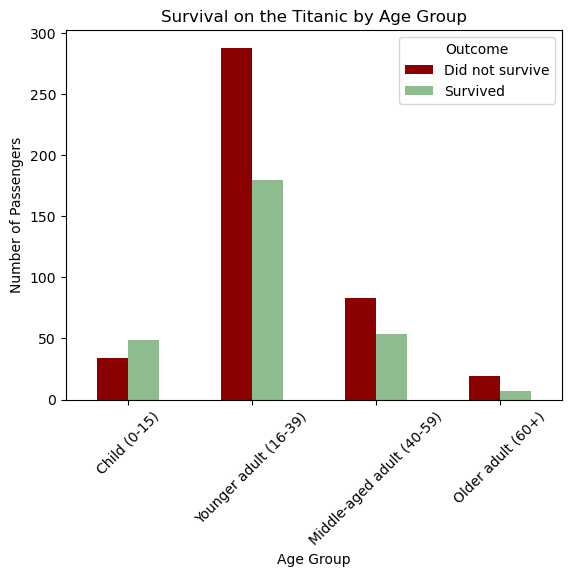

In [11]:
# Create a count chart in a separate cell.
pd.crosstab(age_known_df["age_group"], age_known_df["Survived"]).reindex(age_order).plot(kind="bar", color=["darkred", "darkseagreen"])

plt.title("Survival on the Titanic by Age Group")
plt.ylabel("Number of Passengers")
plt.xlabel("Age Group")
plt.xticks(rotation=45)
plt.legend(["Did not survive", "Survived"], title="Outcome")
plt.show()

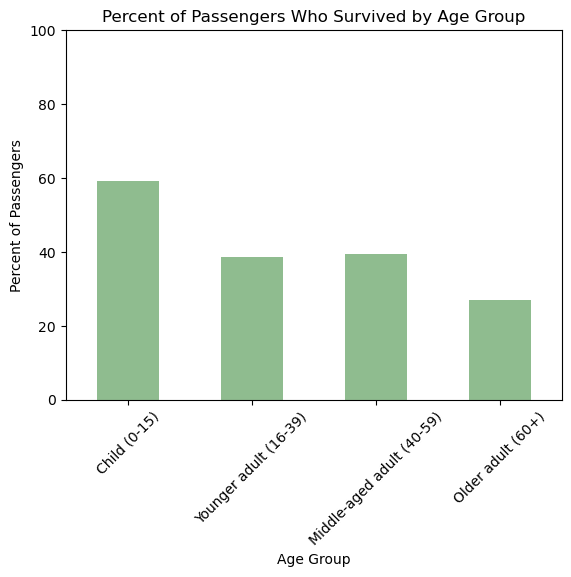

In [12]:
# Plot the conditional percentage who survived.
pd.crosstab(age_known_df["age_group"], age_known_df["Survived"], normalize="index").mul(100).round(2).reindex(age_order)[1].plot(kind="bar", color="darkseagreen")

plt.title("Percent of Passengers Who Survived by Age Group")
plt.ylabel("Percent of Passengers")
plt.xlabel("Age Group")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.show()

### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [13]:
# Create and display the count cross-tab.
pd.crosstab(titanic_df["Sex"], titanic_df["Survived"])

Survived,0,1
Sex,,
female,81,233
male,468,109


In [14]:
# Calculate conditional percentages and display only the survived column.
pd.crosstab(titanic_df["Sex"], titanic_df["Survived"], normalize="index").mul(100).round(2)[1]

Sex
female    74.20
male      18.89
Name: 1, dtype: float64

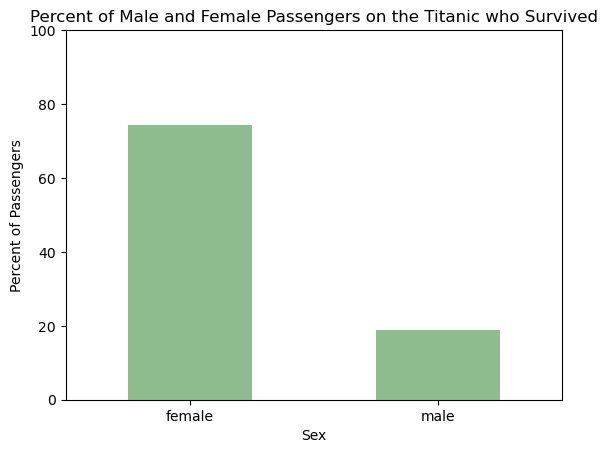

In [15]:
# Plot the conditional percentage who survived.
pd.crosstab(titanic_df["Sex"], titanic_df["Survived"], normalize="index").mul(100)[1].plot(kind="bar", color=["darkseagreen"])

plt.title("Percent of Male and Female Passengers on the Titanic who Survived")
plt.ylabel("Percent of Passengers")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()

### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [16]:
# Create and display the count cross-tab.
pd.crosstab(titanic_df["Pclass"], titanic_df["Survived"])

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [17]:
# Calculate conditional percentages and display only the survived column.
pd.crosstab(titanic_df["Pclass"], titanic_df["Survived"], normalize="index").mul(100).round(2)[1]

Pclass
1    62.96
2    47.28
3    24.24
Name: 1, dtype: float64

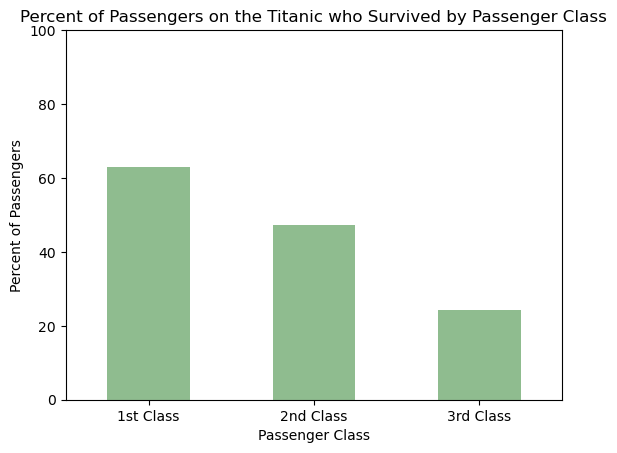

In [18]:
# Plot the conditional percentage who survived.
pd.crosstab(titanic_df["Pclass"], titanic_df["Survived"], normalize="index").mul(100)[1].plot(kind="bar", color=["darkseagreen"])

plt.title("Percent of Passengers on the Titanic who Survived by Passenger Class")
plt.ylabel("Percent of Passengers")
plt.xlabel("Passenger Class")
plt.xticks([0, 1, 2], ["1st Class", "2nd Class", "3rd Class"], rotation=0)
plt.ylim(0, 100)
plt.show()

### Parents or children aboard

Compare `Parch or your derived group` with `Survived` using your Data-step choices.


In [19]:
# Create and display the count cross-tab.
parch_order = ["None", "One", "Two or more"]

pd.crosstab(titanic_df["parch_group"], titanic_df["Survived"]).reindex(parch_order)

Survived,0,1
parch_group,,
None,445,233
One,53,65
Two or more,51,44


In [20]:
# Calculate conditional percentages and display only the survived column.
pd.crosstab(titanic_df["parch_group"], titanic_df["Survived"], normalize="index").mul(100).round(2).reindex(parch_order)[1]

parch_group
None           34.37
One            55.08
Two or more    46.32
Name: 1, dtype: float64

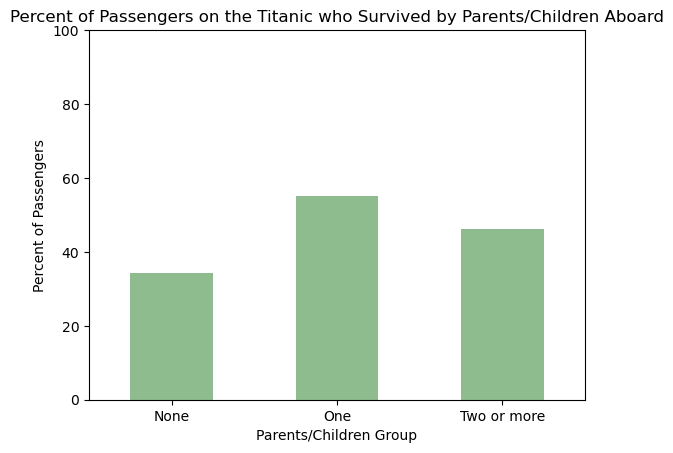

In [21]:
# Plot the conditional percentage who survived.
pd.crosstab(titanic_df["parch_group"], titanic_df["Survived"], normalize="index").mul(100)[1].reindex(parch_order).plot(kind="bar", color=["darkseagreen"])

plt.title("Percent of Passengers on the Titanic who Survived by Parents/Children Aboard")
plt.ylabel("Percent of Passengers")
plt.xlabel("Parents/Children Group")
plt.xticks([0, 1, 2], ["None", "One", "Two or more"], rotation=0)
plt.ylim(0, 100)
plt.show()

### Siblings or spouse aboard

Compare `SibSp or your derived group` with `Survived` using your Data-step choices.


In [22]:
# Create and display the count cross-tab.
sibsp_order = ["None", "One", "Two or more"]

pd.crosstab(titanic_df["sibsp_group"], titanic_df["Survived"]).reindex(sibsp_order)

Survived,0,1
sibsp_group,,
None,398,210
One,97,112
Two or more,54,20


In [23]:
# Calculate conditional percentages and display only the survived column.
pd.crosstab(titanic_df["sibsp_group"], titanic_df["Survived"], normalize="index").mul(100).round(2).reindex(sibsp_order)[1]

sibsp_group
None           34.54
One            53.59
Two or more    27.03
Name: 1, dtype: float64

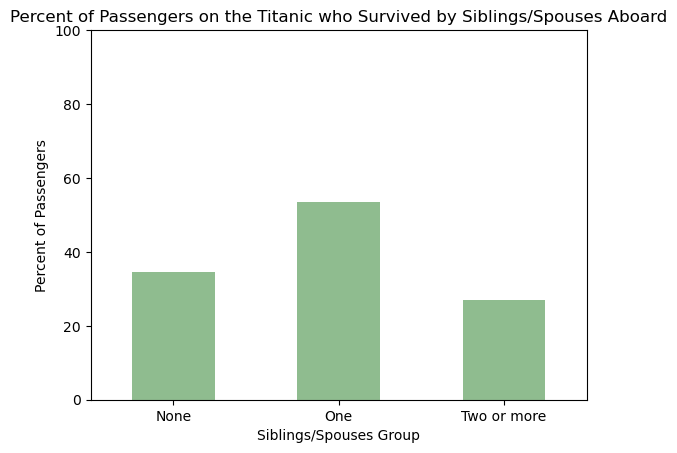

In [24]:
# Plot the conditional percentage who survived.
pd.crosstab(titanic_df["sibsp_group"], titanic_df["Survived"], normalize="index").mul(100)[1].reindex(sibsp_order).plot(kind="bar", color=["darkseagreen"])

plt.title("Percent of Passengers on the Titanic who Survived by Siblings/Spouses Aboard")
plt.ylabel("Percent of Passengers")
plt.xlabel("Siblings/Spouses Group")
plt.xticks([0, 1, 2], ["None", "One", "Two or more"], rotation=0)
plt.ylim(0, 100)
plt.show()

### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [25]:
# Create and display the count cross-tab.
embarked_known_df = titanic_df[titanic_df["Embarked"].notna()].copy()

pd.crosstab(embarked_known_df["Embarked"], embarked_known_df["Survived"])

Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,217


In [26]:
# Calculate conditional percentages and display only the survived column.
pd.crosstab(embarked_known_df["Embarked"], embarked_known_df["Survived"], normalize="index").mul(100).round(2)[1]

Embarked
C    55.36
Q    38.96
S    33.70
Name: 1, dtype: float64

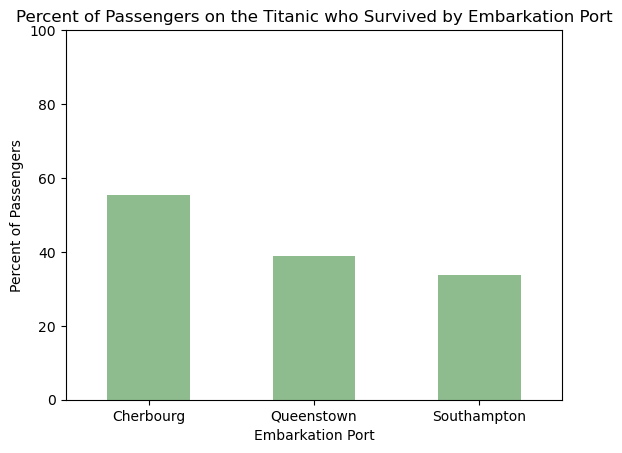

In [27]:
# Plot the conditional percentage who survived.
pd.crosstab(embarked_known_df["Embarked"], embarked_known_df["Survived"], normalize="index").mul(100)[1].plot(kind="bar", color=["darkseagreen"])

plt.title("Percent of Passengers on the Titanic who Survived by Embarkation Port")
plt.ylabel("Percent of Passengers")
plt.xlabel("Embarkation Port")
plt.xticks([0, 1, 2], ["Cherbourg", "Queenstown", "Southampton"], rotation=0)
plt.ylim(0, 100)
plt.show()

### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.


| Feature | Highest-survival category, percentage, and group size | Lowest-survival category, percentage, and group size |
| --- | --- | --- |
| Sex | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Child (0–15): 59.0% survived (49 of 83 passengers with known ages). | Older adult (60+): 26.9% survived (7 of 26 passengers with known ages). |
| Passenger class | 1st class: 63.0% survived (136 of 216 passengers). | 3rd class: 24.2% survived (119 of 491 passengers). |
| Parents or children aboard | One: 55.1% survived (65 of 118 passengers). | None: 34.4% survived (233 of 678 passengers). |
| Siblings or spouse aboard | One: 53.6% survived (112 of 209 passengers). | Two or more: 27.0% survived (20 of 74 passengers). |
| Embarkation port | Cherbourg: 55.4% survived (93 of 168 passengers). | Southampton: 33.7% survived (217 of 644 passengers). |


**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer: One joint percentage is that 6.86% of the 714 passengers with known ages were children who survived. That uses all 714 known-age passengers as the denominator. One conditional percentage is that 59.04% of children survived. That uses only the 83 children as the denominator. The conditional percentage answers the survival-likelihood question more clearly because it compares survival within each age group. The joint percentage also depends on how many people were in that age group, so a small group can have a low joint percentage even if its survival rate is high. For example, children had the highest survival rate, but they were a small part of the known-age passengers, so their joint survival percentage is small.

## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [28]:
# Check age-group boundaries and unknown ages.
age_check_order = [
    "Child (0-15)",
    "Younger adult (16-39)",
    "Middle-aged adult (40-59)",
    "Older adult (60+)",
]

print(titanic_df.groupby("age_group")["Age"].agg(["count", "min", "max"]).reindex(age_check_order))
print("Unknown age count:", titanic_df["Age"].isnull().sum())
print("Known ages assigned to Unknown:",((titanic_df["age_group"] == "Unknown") & titanic_df["Age"].notna()).sum(),)

                           count    min   max
age_group                                    
Child (0-15)                  83   0.42  15.0
Younger adult (16-39)        468  16.00  39.0
Middle-aged adult (40-59)    137  40.00  59.0
Older adult (60+)             26  60.00  80.0
Unknown age count: 177
Known ages assigned to Unknown: 0


In [29]:
# Check travel-companion category mappings if you created grouped features.
print("Parch mapping:")
print(pd.crosstab(titanic_df["Parch"], titanic_df["parch_group"]))
print("\nSibSp mapping:")
print(pd.crosstab(titanic_df["SibSp"], titanic_df["sibsp_group"]))

Parch mapping:
parch_group  None  One  Two or more
Parch                              
0             678    0            0
1               0  118            0
2               0    0           80
3               0    0            5
4               0    0            4
5               0    0            5
6               0    0            1

SibSp mapping:
sibsp_group  None  One  Two or more
SibSp                              
0             608    0            0
1               0  209            0
2               0    0           28
3               0    0           16
4               0    0           18
5               0    0            5
8               0    0            7


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer: The checks match what I intended. The age groups run from 0.42 to 15 for children, 16 to 39 for younger adults, 40 to 59 for middle-aged adults, and 60 to 80 for older adults. There are 177 unknown ages, and no known age is labeled Unknown. The four known-age groups add up to 714, which is the age denominator.

The Parch mapping looks right: 0 is None, 1 is One, and 2 or more is Two or more. The SibSp mapping uses the same groups. Each original value lands in only one group, and the group totals are 678, 118, and 95 for Parch and 608, 209, and 74 for SibSp.

The denominators also match what I planned: 891 for Sex, Pclass, Parch, and SibSp; 889 for Embarked because two ports are missing; and 714 for age because 177 ages are unknown. I checked that the percentages use the whole group, not just survivors. For example, female survival is 233 out of 314, not 233 out of all survivors, and 1st-class survival is 136 out of 216. The raw counts can look different from the percentages because the groups are different sizes. For example, None has more Parch survivors in total than One, but None is also a much bigger group, so its survival percentage is lower.

I would be suspicious if an age group had a minimum or maximum outside its boundary, if a known age showed up in Unknown, if one original Parch or SibSp value appeared in more than one group, or if a percentage used only survivors. I didn’t find any of those problems in this check.

The small groups that limit interpretation are the 60+ age group with 26 people and the SibSp Two or more group with 74 people. One person changes the 60+ percentage by about 4 points, so I’ll be careful with it. Queenstown is also smallish at 77, and the 177 unknown ages mean the age comparison only covers 714 passengers.

## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.


| Profile element | Most likely profile: category and evidence | Least likely profile: category and evidence |
| --- | --- | --- |
| Sex | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Middle-aged adult (40–59): 39.4% survived (54 of 137 passengers with known ages). | Older adult (60+): 26.9% survived (7 of 26 passengers with known ages). |
| Passenger class | 1st class: 63.0% survived (136 of 216 passengers). | 3rd class: 24.2% survived (119 of 491 passengers). |
| Parents or children aboard | One: 55.1% survived (65 of 118 passengers). | None: 34.4% survived (233 of 678 passengers). |
| Siblings or spouse aboard | One: 53.6% survived (112 of 209 passengers). | None: 34.5% survived (210 of 608 passengers). |
| Embarkation port | Cherbourg: 55.4% survived (93 of 168 passengers). | Southampton: 33.7% survived (217 of 644 passengers). |

The lowest-survival `SibSp` category was Two or more (27.0%, 20 of 74), but no passenger matched the other five least-likely choices with that category, so the final profile uses None (34.5%, 210 of 608).

**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer: 
Most likely profile:
The most likely survivor is a woman in her 40s, traveling first class from Cherbourg with one parent or child and one sibling or spouse. Female, first class, and both travel-companion groups are the highest-survival categories. Cherbourg is also the highest port, though that probably overlaps with class. The tradeoff is age: no child matched the other five strongest categories, so I used middle-aged adults, the highest adult age group at 39.4%. This is the best-fitting combination, not a guarantee.

Least likely profile:
The least likely survivor, according to the dataset’s family-count columns, is an older man in third class from Southampton, with `Parch` and `SibSp` both recorded as none. Male, 60+, third class, no parents/children, and Southampton are all the lowest-survival categories. The tradeoff is siblings/spouses: Two or more had the lowest survival rate, but no one matches that with the other five choices, so I used none, the next-lowest at 34.5%. That makes the profile a little less extreme, but it still fits the low-survival pattern. The biography shows one limit of the data: Svensson was actually traveling with his son, even though the dataset records no parents/children.

### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [30]:
# Create most_likely_df and display matching names and profile features.
most_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "female")
    & (titanic_df["age_group"] == "Middle-aged adult (40-59)")
    & (titanic_df["Pclass"] == 1)
    & (titanic_df["parch_group"] == "One")
    & (titanic_df["sibsp_group"] == "One")
    & (titanic_df["Embarked"] == "C")
]

most_likely_df[
    ["PassengerId", "Name", "Sex", "age_group", "Pclass",
     "parch_group", "sibsp_group", "Embarked"]
]

,PassengerId,Name,Sex,age_group,Pclass,parch_group,sibsp_group,Embarked
319,320,"Spedden, Mrs. Frederic Oakley (Margaretta Corn...",female,Middle-aged adult (40-59),1,One,One,C


In [31]:
# Create least_likely_df and display matching names and profile features.
least_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "male")
    & (titanic_df["age_group"] == "Older adult (60+)")
    & (titanic_df["Pclass"] == 3)
    & (titanic_df["parch_group"] == "None")
    & (titanic_df["sibsp_group"] == "None")
    & (titanic_df["Embarked"] == "S")
]

least_likely_df[
    ["PassengerId", "Name", "Sex", "age_group", "Pclass",
     "parch_group", "sibsp_group", "Embarked"]
]

,PassengerId,Name,Sex,age_group,Pclass,parch_group,sibsp_group,Embarked
326,327,"Nysveen, Mr. Johan Hansen",male,Older adult (60+),3,None,None,S
851,852,"Svensson, Mr. Johan",male,Older adult (60+),3,None,None,S


**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer: The most likely filter matches one passenger, Spedden, Mrs. Frederic Oakley (Margaretta Corning Stone), PassengerId 320. She matches all six revised choices. The original child version had no matches, so I changed only the age group from Child to Middle-aged adult. Middle-aged adults had 39.4% survival, just above younger adults at 38.5%, and this kept the other five strongest categories.

The least likely filter matches two passengers, Nysveen, Mr. Johan Hansen (PassengerId 327) and Svensson, Mr. Johan (PassengerId 852). Both match all six revised choices. The original version with two or more siblings/spouses had no matches, so I changed only that element to none. None has the next-lowest survival rate at 34.5%, and changing the age group would have moved the profile further from the lowest age category.

I did not filter on `Survived`. I revised based on which combinations exist and on the category percentages, not on choosing a passenger with a particular outcome.

### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: I chose Spedden, Mrs. Frederic Oakley (Margaretta Corning Stone), PassengerId 320. The biography identifies her as Mrs Margaretta Corning Spedden, known as “Daisy,” a first-class passenger who embarked at Cherbourg. The ticket number 16966 and cabin E34 match the dataset, and she was rescued in lifeboat 3. The dataset lists her age as 40, while the biography says 39 years, 4 months, and 26 days, but the other details line up, so I’m confident it’s the same person. One interesting fact is that she wrote and illustrated a storybook for her son Douglas, told through the eyes of his toy bear, about their trip and the sinking. It was later published as Polar, the Titanic Bear.

Biography: https://www.encyclopedia-titanica.org/titanic-survivor/margaretta-corning-spedden.html

**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: I chose Svensson, Mr. Johan, PassengerId 852. The biography identifies him as Mr Johan Svensson, a Swedish third-class passenger who embarked at Southampton. The ticket number 347060 matches the dataset, and the age of 74 matches. He was traveling with his son Amandus, who was listed as Johan Ekström. One interesting fact is that at 74 he was the oldest person aboard the Titanic. Both he and his son died in the sinking, and their bodies were never identified.

There is a discrepancy with the dataset: it records Parch = 0 and SibSp = 0, but a son traveling with him should count as a child under Parch. I’m reporting the disagreement rather than changing the data. The consecutive ticket numbers, 347060 and 347061, support the biography’s account that they traveled together.

Biography: https://www.encyclopedia-titanica.org/titanic-victim/johan-svensson.html

After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [32]:
# Display the selected passengers and their recorded survival outcomes.
selected_ids = [320, 852]

titanic_df.loc[
    titanic_df["PassengerId"].isin(selected_ids),
    ["PassengerId", "Name", "Sex", "age_group", "Pclass",
     "parch_group", "sibsp_group", "Embarked", "Survived"]
]

,PassengerId,Name,Sex,age_group,Pclass,parch_group,sibsp_group,Embarked,Survived
319,320,"Spedden, Mrs. Frederic Oakley (Margaretta Corn...",female,Middle-aged adult (40-59),1,One,One,C,1
851,852,"Svensson, Mr. Johan",male,Older adult (60+),3,None,None,S,0


**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Your answer: Yes, both outcomes match the profile labels. Spedden has Survived = 1, so she survived, which fits the most-likely profile. Svensson has Survived = 0, so he died, which fits the least-likely profile. That doesn’t prove the profiles caused the outcomes or that everyone with the same characteristics had the same result. The profiles describe group tendencies, and an individual can still contradict them.

There is one biography discrepancy. The dataset records Svensson with Parch = 0 and SibSp = 0, but Encyclopedia Titanica says he was traveling with his son Amandus. A son should count as a child under Parch, so the dataset appears incomplete for this passenger. I’m reporting the disagreement rather than changing the data. The only other small difference is Spedden’s age: the dataset says 40, while the biography says about 39 years and 4 months, which looks like a rounding or record-keeping difference.

### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer: I’d recommend Margaretta “Daisy” Spedden as the most likely survivor and Johan Svensson as the least likely. Spedden fits the strongest profile: female (74.2% survived), first class (63.0%), one parent/child aboard (55.1%), one sibling/spouse aboard (53.6%), and Cherbourg (55.4%). Her age group is middle-aged (39.4%), which is a compromise: no child matched the other five strongest categories, so I changed only the age group to the highest adult group. The biography adds a strong human detail: she survived in lifeboat 3 and later wrote the storybook that became Polar, the Titanic Bear.

Svensson fits the weakest profile in the dataset: male (18.9%), 60+ (26.9%), third class (24.2%), `Parch` none (34.4%), `SibSp` none (34.5%), and Southampton (33.7%). He was the oldest person aboard and died with his son. The biography also shows a data limitation: the dataset records no parents/children, but he was traveling with his son, so the `Parch` value appears incomplete. “Traveling alone” here only means the dataset records no family members in `Parch` or `SibSp`; it is not a literal description of his companions. The tradeoff is that “no siblings/spouse” is not the absolute lowest-survival `SibSp` group. “Two or more” had a lower survival rate at 27.0%, but no older third-class man from Southampton with no parents/children and two or more siblings/spouses exists in the data, so I changed only that element.

Compared with my initial prediction, I got the sex, class, and small-family idea mostly right. I had to change the most likely age from child to middle-aged. The least-likely profile looks closer to my original “traveling alone” guess, but that is only because the dataset records `Parch = 0` and `SibSp = 0`; the biography says Svensson was with his son. I didn’t make a port prediction at the start, but the data showed Cherbourg highest and Southampton lowest. That could just reflect the class mix, so I wouldn’t treat the port as a cause. These are group patterns, not guaranteed individual outcomes.

## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer: The director should avoid treating these profiles as guarantees or as causal explanations. The percentages come from separate one-feature comparisons, so they don’t tell us the survival rate for a person with all six characteristics combined. The features are also related: sex, class, age, and port overlap, and the port difference probably reflects the class mix rather than the port itself causing survival. I also shouldn’t multiply the percentages together, because that assumes the features are independent and would give a false sense of precision.

There are small groups: only 26 passengers are 60+, only 74 have two or more siblings/spouses, and Queenstown has only 77 passengers. One person can move those percentages by several points. The age comparison leaves out 177 passengers with unknown ages, and the port comparison leaves out 2 passengers with missing ports. The dataset is also a subset of 891 passengers, not the full ship. My category choices matter too: changing the age boundaries or grouping Parch and SibSp differently could change the percentages. Finally, the dataset and biographies can disagree in small ways, like Spedden’s age being 40 in the dataset and about 39 years and 4 months on Encyclopedia Titanica. So the profiles are useful descriptions of group patterns, not proof of what caused any individual to live or die.

The Svensson case is a concrete limitation: the dataset says he had no parents/children aboard, but the biography says he was traveling with his son. That means Parch and SibSp may not capture every real family relationship, so the travel-companion categories should be treated as recorded categories, not as a complete description of who was with each passenger.

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I used AI to help plan the code and draft some of the wording. One suggestion I modified was the age grouping. The first version used 16–59 as one adult group, but I changed it to 16–39 and 40–59 because the original group was too broad and could hide the difference between younger and middle-aged adults. I also checked the code outputs and the Encyclopedia Titanica pages myself, and I revised the most-likely profile from a child to a middle-aged adult when the six-way child combination had no matches.

## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
